In [1]:
import sys

print(sys.executable)



C:\MCDI501-Framingham\.venv\Scripts\python.exe


# Evaluación Sumativa 2
## Validación, simulación y métodos de remuestreo

**Asignatura:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Proyecto:** Análisis estadístico del riesgo de enfermedad coronaria a diez años  
**Dataset:** Framingham Heart Study  
**Docente:** Jean Paul Maidana González  
**Fase:** 3 — Desarrollo del proyecto

### Objetivo general

Evaluar la estabilidad, incertidumbre y robustez de los resultados
obtenidos en la Sumativa 1 mediante bootstrap no paramétrico,
pruebas de permutación, simulación Monte Carlo y análisis de sensibilidad.

### Vinculación con la Sumativa 1

Se reutilizarán los parámetros estimados, intervalos de confianza,
pruebas de hipótesis y correlaciones previamente calculados
sobre el conjunto de datos Framingham.

## 1. Configuración del entorno de trabajo

En esta sección se importan las bibliotecas necesarias para el análisis
estadístico, la manipulación de datos y la generación de gráficos.

Se establece una semilla aleatoria fija para garantizar la
reproducibilidad de los experimentos.

Las simulaciones y procedimientos de remuestreo utilizarán NumPy y
SciPy. Pandas permitirá manipular el dataset, mientras que Matplotlib
y Seaborn se utilizarán para visualizar los resultados.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Semilla para reproducibilidad
SEMILLA = 42

# Generador pseudoaleatorio
rng = np.random.default_rng(SEMILLA)

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid", context="notebook")

print("Bibliotecas cargadas correctamente.")
print("Semilla configurada:", SEMILLA)

Bibliotecas cargadas correctamente.
Semilla configurada: 42


## 2. Localización del proyecto y del dataset

Para mantener la reproducibilidad del análisis, se utilizarán rutas
relativas a la carpeta raíz del repositorio.

El programa buscará automáticamente el archivo `framingham.csv`
en la carpeta `fase-1/datos/raw/`.

También se definirán las rutas donde se almacenarán las figuras y
los resultados de la Sumativa 2.

Los datos originales no serán modificados.

In [3]:
def encontrar_raiz(inicio=None):
    inicio = Path(inicio or Path.cwd()).resolve()

    for candidata in (inicio, *inicio.parents):
        archivo = (
            candidata / "fase-1" / "datos"
            / "raw" / "framingham.csv"
        )

        if archivo.exists():
            return candidata

    raise FileNotFoundError(
        "No se encontró el archivo framingham.csv."
    )


RAIZ = encontrar_raiz()

RUTA_DATOS = (
    RAIZ / "fase-1" / "datos" / "raw" / "framingham.csv"
)

DIR_S2 = RAIZ / "fase-3" / "sumativa-2"
DIR_FIGURAS = DIR_S2 / "figuras"
DIR_RESULTADOS = DIR_S2 / "resultados"

print("Raíz del proyecto:", RAIZ)
print("Ruta del dataset:", RUTA_DATOS)

Raíz del proyecto: C:\MCDI501-Framingham
Ruta del dataset: C:\MCDI501-Framingham\fase-1\datos\raw\framingham.csv


## 3. Carga y verificación inicial del dataset

Se carga el conjunto de datos Framingham desde su ubicación original.

Posteriormente, se crea una copia de trabajo para preservar los datos
originales y se verifica que las dimensiones coincidan con las
documentadas en la Sumativa 1.

El conjunto original contiene 4.238 observaciones y 16 variables.

Esta validación permite comprobar que ambos trabajos utilizan la
misma fuente de información.

In [4]:
# Cargar el dataset original
df = pd.read_csv(RUTA_DATOS)

# Crear una copia para el análisis
df_analisis = df.copy()

# Verificar dimensiones
print("Número de filas:", df_analisis.shape[0])
print("Número de columnas:", df_analisis.shape[1])

# Mostrar las primeras observaciones
display(df_analisis.head())

Número de filas: 4238
Número de columnas: 16


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## 4. Validación de intervalos mediante bootstrap

### 4.1. Selección de parámetros de la Sumativa 1

Se seleccionan tres parámetros estimados previamente: la edad media,
la presión arterial sistólica media y el colesterol total medio.

El objetivo es evaluar la estabilidad de sus estimaciones mediante
bootstrap no paramétrico, utilizando 10.000 remuestras.

El bootstrap consiste en generar nuevas muestras a partir de los datos
observados, seleccionando registros aleatoriamente **con reemplazo**.

Se conservarán únicamente los valores disponibles para cada variable,
manteniendo los tamaños muestrales utilizados en la Sumativa 1.

Posteriormente, se calcularán intervalos de confianza al 95 % mediante
los métodos percentil y BCa, comparándolos con los intervalos clásicos.

In [5]:
# Parámetros seleccionados de la Sumativa 1
variables_bootstrap = {
    "Edad": "age",
    "Presión sistólica": "sysBP",
    "Colesterol total": "totChol"
}

# Preparar muestras sin valores faltantes
datos_bootstrap = {}

for nombre, columna in variables_bootstrap.items():

    datos = df_analisis[columna].dropna().to_numpy()

    datos_bootstrap[nombre] = datos

    print(
        f"{nombre}: "
        f"n = {len(datos)}, "
        f"media = {np.mean(datos):.2f}"
    )

Edad: n = 4238, media = 49.58
Presión sistólica: n = 4238, media = 132.35
Colesterol total: n = 4188, media = 236.72


### 4.2. Estimación de intervalos bootstrap

Se implementa bootstrap no paramétrico con 10.000 remuestras
para cada uno de los tres parámetros seleccionados.

Se estiman intervalos de confianza al 95 % mediante dos métodos:

- **Percentil:** utiliza los percentiles 2,5 y 97,5 de la
  distribución bootstrap.
- **BCa:** incorpora correcciones por sesgo y aceleración
  para ajustar los límites del intervalo.

La media muestral se utiliza como estadístico de interés.
Se fija una semilla aleatoria para garantizar la reproducibilidad.

In [6]:
# Número de remuestras bootstrap
N_BOOTSTRAP = 10_000
rng_bootstrap = np.random.default_rng(SEMILLA)
resultados_bootstrap = {}

for nombre, datos in datos_bootstrap.items():
    resultado = stats.bootstrap(
        (datos,), statistic=np.mean, confidence_level=0.95,
        n_resamples=N_BOOTSTRAP, method="BCa", batch=500,
        rng=rng_bootstrap
    )
    medias_bootstrap = resultado.bootstrap_distribution
    ic_percentil = np.percentile(medias_bootstrap, [2.5, 97.5])
    ic_bca = resultado.confidence_interval
    resultados_bootstrap[nombre] = {
        "media": np.mean(datos), "percentil": ic_percentil,
        "bca": (ic_bca.low, ic_bca.high),
        "distribucion": medias_bootstrap
    }
    print(f"\n{nombre}")
    print(f"Media: {np.mean(datos):.4f}")
    print(f"IC percentil: {ic_percentil}")
    print(f"IC BCa: [{ic_bca.low:.4f}, {ic_bca.high:.4f}]")


Edad
Media: 49.5849
IC percentil: [49.32586126 49.84616564]
IC BCa: [49.3268, 49.8471]



Presión sistólica
Media: 132.3524
IC percentil: [131.68805156 133.01086008]
IC BCa: [131.7004, 133.0231]



Colesterol total
Media: 236.7216
IC percentil: [235.36556829 238.0499224 ]
IC BCa: [235.4043, 238.1034]


### 4.3. Comparación con los intervalos clásicos

Se recalculan los intervalos de confianza clásicos utilizados en la
Sumativa 1 y se comparan con los intervalos bootstrap percentil y BCa.

El intervalo clásico para la media se obtiene mediante la distribución
t de Student, debido a que la desviación estándar poblacional es
desconocida.

In [7]:
def intervalo_clasico_media(datos, confianza=0.95):

    n = len(datos)
    media = np.mean(datos)
    desviacion = np.std(datos, ddof=1)

    error_estandar = desviacion / np.sqrt(n)

    alfa = 1 - confianza

    t_critico = stats.t.ppf(
        1 - alfa / 2,
        df=n - 1
    )

    margen = t_critico * error_estandar

    return (
        media - margen,
        media + margen
    )
    

In [8]:
filas_comparacion = []

for nombre, datos in datos_bootstrap.items():

    ic_clasico = intervalo_clasico_media(datos)

    ic_percentil = resultados_bootstrap[nombre]["percentil"]
    ic_bca = resultados_bootstrap[nombre]["bca"]

    filas_comparacion.append({
        "Variable": nombre,
        "Media": np.mean(datos),
        "Clásico inferior": ic_clasico[0],
        "Clásico superior": ic_clasico[1],
        "Percentil inferior": ic_percentil[0],
        "Percentil superior": ic_percentil[1],
        "BCa inferior": ic_bca[0],
        "BCa superior": ic_bca[1]
    })

tabla_comparacion = (
    pd.DataFrame(filas_comparacion)
    .set_index("Variable")
    .round(4)
)

display(tabla_comparacion)

,Media,Clásico inferior,Clásico superior,Percentil inferior,Percentil superior,BCa inferior,BCa superior
Variable,,,,,,,
Edad,49.5849,49.3268,49.8431,49.3259,49.8462,49.3268,49.8471
Presión sistólica,132.3524,131.6887,133.0161,131.6881,133.0109,131.7004,133.0231
Colesterol total,236.7216,235.3707,238.0724,235.3656,238.0499,235.4043,238.1034


### Figura 1. Distribuciones bootstrap y comparación de intervalos

Se representan las distribuciones de las 10.000 medias obtenidas mediante
bootstrap. Las líneas verticales permiten comparar la media observada y
los límites de los intervalos clásico, percentil y BCa.

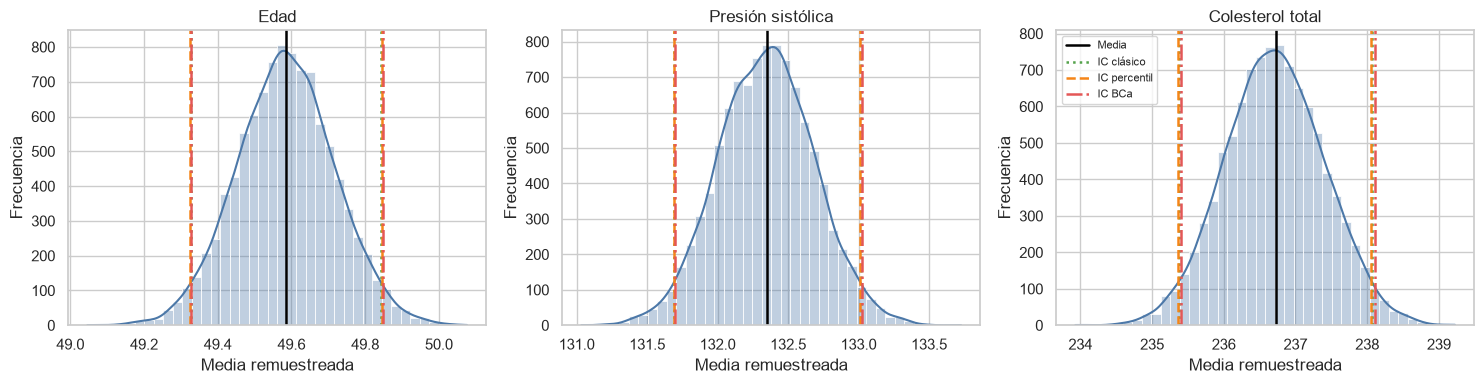

Figura guardada en: C:\MCDI501-Framingham\fase-3\sumativa-2\figuras\figura_1_bootstrap_intervalos.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for eje, (nombre, datos) in zip(
    axes,
    datos_bootstrap.items()
):

    resultados = resultados_bootstrap[nombre]

    distribucion = resultados["distribucion"]
    media = resultados["media"]
    ic_percentil = resultados["percentil"]
    ic_bca = resultados["bca"]
    ic_clasico = intervalo_clasico_media(datos)

    # Distribución de las medias bootstrap
    sns.histplot(
        distribucion,
        bins=40,
        kde=True,
        color="#4C78A8",
        alpha=0.35,
        ax=eje
    )

    # Media observada
    eje.axvline(
        media,
        color="black",
        linewidth=1.8,
        label="Media"
    )

    # Intervalo clásico
    eje.axvline(
        ic_clasico[0],
        color="#54A24B",
        linestyle=":",
        linewidth=1.8,
        label="IC clásico"
    )
    eje.axvline(
        ic_clasico[1],
        color="#54A24B",
        linestyle=":",
        linewidth=1.8
    )

    # Intervalo percentil
    eje.axvline(
        ic_percentil[0],
        color="#F58518",
        linestyle="--",
        linewidth=1.8,
        label="IC percentil"
    )
    eje.axvline(
        ic_percentil[1],
        color="#F58518",
        linestyle="--",
        linewidth=1.8
    )

    # Intervalo BCa
    eje.axvline(
        ic_bca[0],
        color="#E45756",
        linestyle="-.",
        linewidth=1.8,
        label="IC BCa"
    )
    eje.axvline(
        ic_bca[1],
        color="#E45756",
        linestyle="-.",
        linewidth=1.8
    )

    eje.set_title(nombre)
    eje.set_xlabel("Media remuestreada")
    eje.set_ylabel("Frecuencia")

axes[-1].legend(fontsize=8)

plt.tight_layout()

# Crear la carpeta si todavía no existe
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

# Guardar la figura
ruta_figura = DIR_FIGURAS / "figura_1_bootstrap_intervalos.png"

fig.savefig(
    ruta_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:", ruta_figura)

### 4.4. Interpretación de los intervalos bootstrap

Los intervalos clásico, percentil y BCa presentan límites muy similares
para las tres medias. El clásico usa la aproximación normal de la media; el
percentil usa directamente los cuantiles bootstrap y puede ser sensible a
sesgo o asimetría; BCa corrige sesgo y aceleración. Su cercanía, junto con
los tamaños muestrales grandes, indica estabilidad frente al remuestreo.

Esto respalda las estimaciones descriptivas de la Sumativa 1, pero no
elimina limitaciones por valores extremos, datos ausentes,
representatividad o el carácter observacional del estudio.

## 5. Validación mediante una prueba de permutación

En la Sumativa 1, Welch mostró una diferencia significativa en la presión
sistólica media entre quienes desarrollaron CHD y quienes no. Como
comprobación complementaria se aplica una permutación bilateral con 10.000
repeticiones y significancia de 0,05.

### Hipótesis

- **H₀:** la distribución de presión sistólica es la misma en ambos grupos;
  las etiquetas son intercambiables.
- **H₁:** las distribuciones difieren, lo que puede expresarse mediante una
  diferencia de sus medias.

El estadístico es la media con CHD menos la media sin CHD. Las etiquetas se
mezclan 10.000 veces conservando los tamaños de los grupos. El valor p
bilateral corresponde a la proporción corregida de diferencias permutadas
al menos tan extremas como la observada. La permutación cruda supone
intercambiabilidad; por ello no es idéntica a Welch bajo heterocedasticidad.

In [10]:
# Seleccionar las variables necesarias
datos_permutacion = (
    df_analisis[["sysBP", "TenYearCHD"]]
    .dropna()
)

# Convertir las columnas en arreglos de NumPy
presion = datos_permutacion["sysBP"].to_numpy()
etiquetas = datos_permutacion["TenYearCHD"].to_numpy()

# Construir los grupos originales
presion_con_chd = presion[etiquetas == 1]
presion_sin_chd = presion[etiquetas == 0]

# Diferencia observada: con CHD menos sin CHD
diferencia_observada = (
    np.mean(presion_con_chd)
    - np.mean(presion_sin_chd)
)

print("Personas con CHD:", len(presion_con_chd))
print("Personas sin CHD:", len(presion_sin_chd))
print(f"Media con CHD: {np.mean(presion_con_chd):.3f} mmHg")
print(f"Media sin CHD: {np.mean(presion_sin_chd):.3f} mmHg")
print(f"Diferencia observada: {diferencia_observada:.3f} mmHg")

Personas con CHD: 644
Personas sin CHD: 3594
Media con CHD: 143.619 mmHg
Media sin CHD: 130.334 mmHg
Diferencia observada: 13.285 mmHg


In [11]:
# Configuración reproducible
rng_perm = np.random.default_rng(SEMILLA)

N_PERMUTACIONES = 10_000

n_total = len(presion)
n_con_chd = len(presion_con_chd)
n_sin_chd = len(presion_sin_chd)

suma_total = np.sum(presion)

# Almacenar las diferencias generadas bajo H0
diferencias_permutadas = np.empty(N_PERMUTACIONES)

for i in range(N_PERMUTACIONES):

    # Seleccionar aleatoriamente quiénes integran el grupo con CHD
    indices_con_chd = rng_perm.choice(
        n_total,
        size=n_con_chd,
        replace=False
    )

    suma_con_chd = np.sum(presion[indices_con_chd])
    suma_sin_chd = suma_total - suma_con_chd

    media_con_chd = suma_con_chd / n_con_chd
    media_sin_chd = suma_sin_chd / n_sin_chd

    diferencias_permutadas[i] = (
        media_con_chd - media_sin_chd
    )

# Valor p bilateral
cantidad_extremas = np.sum(
    np.abs(diferencias_permutadas)
    >= np.abs(diferencia_observada)
)

p_permutacion = (
    (cantidad_extremas + 1)
    / (N_PERMUTACIONES + 1)
)

print("Número de permutaciones:", N_PERMUTACIONES)
print(
    "Media de la distribución nula:",
    round(np.mean(diferencias_permutadas), 4)
)
print(
    "Desviación de la distribución nula:",
    round(np.std(diferencias_permutadas), 4)
)
print("Permutaciones extremas:", cantidad_extremas)
print(f"Valor p de permutación: {p_permutacion:.5f}")

Número de permutaciones: 10000
Media de la distribución nula: 0.0092
Desviación de la distribución nula: 0.944
Permutaciones extremas: 0
Valor p de permutación: 0.00010


### 5.1. Resultados e interpretación

La presión sistólica media fue de 143,62 mmHg en las personas que
desarrollaron enfermedad coronaria y de 130,33 mmHg en quienes no la
desarrollaron. La diferencia observada fue, por tanto, de
aproximadamente 13,29 mmHg.

La distribución generada mediante las 10.000 permutaciones quedó
centrada alrededor de cero. Esto es lo esperado bajo la hipótesis nula,
porque al mezclar aleatoriamente las etiquetas no debería existir una
diferencia sistemática entre los grupos.

Ninguna de las 10.000 permutaciones produjo una diferencia tan extrema
como la observada. Al aplicar la corrección utilizada para la estimación
Monte Carlo, se obtuvo un valor p de aproximadamente 0,00010.

Como este valor es inferior al nivel de significancia de 0,05, se
rechaza la hipótesis nula. Los datos proporcionan evidencia de una
diferencia en la presión sistólica media entre las personas con y sin
enfermedad coronaria a diez años.

En la Sumativa 1, la prueba t de Welch produjo un valor p de
1,210 × 10⁻³⁰, mientras que la prueba de permutación obtuvo un valor p
estimado de 0,00010. Estos valores no deben compararse directamente en
términos de precisión, porque con 10.000 permutaciones la resolución
mínima es aproximadamente 1/10.001. Sin embargo, ambos son muy
inferiores al nivel de significancia de 0,05 y conducen a la misma
decisión estadística: rechazar la hipótesis nula.

En términos descriptivos, el grupo que desarrolló enfermedad coronaria
presentó una presión sistólica media aproximadamente 13,29 mmHg mayor.
Sin embargo, esta diferencia representa una asociación no ajustada y
no demuestra que una presión sistólica elevada sea por sí sola la causa
de la enfermedad. La edad, el sexo, el tabaquismo y otras variables
clínicas pueden actuar como factores de confusión.

### Figura 2. Distribución nula de la prueba de permutación

La distribución representa las diferencias de medias obtenidas al
asignar aleatoriamente las etiquetas de enfermedad coronaria en 10.000
permutaciones. La línea roja muestra la diferencia observada en los
datos originales.

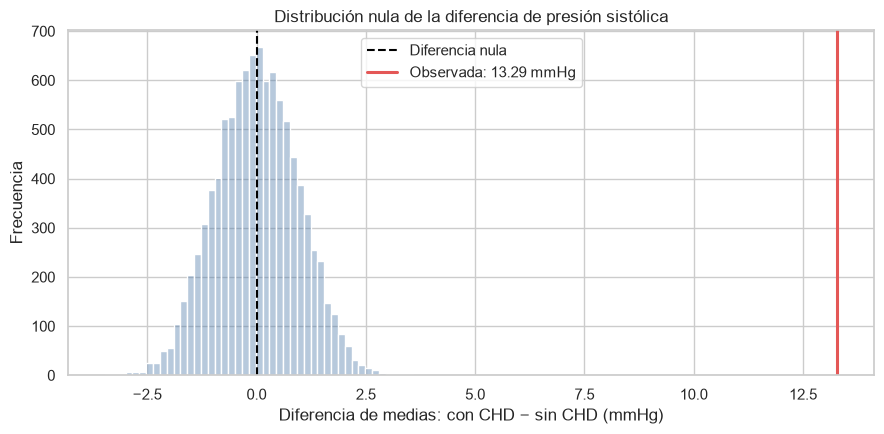

Figura guardada en: C:\MCDI501-Framingham\fase-3\sumativa-2\figuras\figura_2_permutacion_presion_sistolica.png


In [12]:
fig, eje = plt.subplots(figsize=(9, 4.5))

sns.histplot(
    diferencias_permutadas,
    bins=45,
    color="#4C78A8",
    alpha=0.40,
    ax=eje
)

# Centro esperado bajo H0
eje.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Diferencia nula"
)

# Diferencia observada
eje.axvline(
    diferencia_observada,
    color="#E45756",
    linewidth=2.2,
    label=f"Observada: {diferencia_observada:.2f} mmHg"
)

eje.set_title(
    "Distribución nula de la diferencia de presión sistólica"
)
eje.set_xlabel(
    "Diferencia de medias: con CHD − sin CHD (mmHg)"
)
eje.set_ylabel("Frecuencia")
eje.legend()

plt.tight_layout()

ruta_figura_permutacion = (
    DIR_FIGURAS
    / "figura_2_permutacion_presion_sistolica.png"
)

fig.savefig(
    ruta_figura_permutacion,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta_figura_permutacion
)

## 6. Estabilidad de las correlaciones mediante bootstrap

En la Sumativa 1 se calcularon correlaciones entre las variables
numéricas y la ocurrencia de enfermedad coronaria a diez años.

En esta sección se evalúa la estabilidad de las cinco correlaciones de
mayor magnitud: edad, presión sistólica, presión diastólica, glucosa y
colesterol total.

Para cada relación se generarán 3.000 remuestras bootstrap de las filas
disponibles y se calculará un intervalo de confianza percentil del 95 %.

Debido a que `TenYearCHD` es una variable binaria, estas asociaciones
se interpretan como correlaciones punto-biseriales. Este coeficiente es
equivalente a la correlación de Pearson cuando una de las variables
está codificada mediante cero y uno.

Una correlación se considerará estable si su intervalo de confianza no
incluye el valor cero.

In [13]:
variables_correlacion_bootstrap = {
    "Edad": "age",
    "Presión sistólica": "sysBP",
    "Presión diastólica": "diaBP",
    "Glucosa": "glucose",
    "Colesterol total": "totChol"
}

for nombre, variable in variables_correlacion_bootstrap.items():

    datos_correlacion = (
        df_analisis[[variable, "TenYearCHD"]]
        .dropna()
    )

    correlacion = datos_correlacion[variable].corr(
        datos_correlacion["TenYearCHD"]
    )

    print(
        f"{nombre}: "
        f"n = {len(datos_correlacion)}, "
        f"r = {correlacion:.4f}"
    )

Edad: n = 4238, r = 0.2253
Presión sistólica: n = 4238, r = 0.2164
Presión diastólica: n = 4238, r = 0.1453
Glucosa: n = 3850, r = 0.1255
Colesterol total: n = 4188, r = 0.0822


In [14]:
# Número de remuestras para las correlaciones
N_BOOTSTRAP_CORRELACIONES = 3_000

# Un solo generador para toda la sección
rng_correlaciones = np.random.default_rng(SEMILLA)

# Almacenar resultados
resultados_correlaciones = {}

for nombre, variable in variables_correlacion_bootstrap.items():

    # Pares disponibles de la variable y TenYearCHD
    pares = (
        df_analisis[[variable, "TenYearCHD"]]
        .dropna()
        .to_numpy()
    )

    x = pares[:, 0]
    y = pares[:, 1]
    n = len(pares)

    # Correlación observada
    r_observado = np.corrcoef(x, y)[0, 1]

    correlaciones_bootstrap = []

    for i in range(N_BOOTSTRAP_CORRELACIONES):

        # Remuestrear filas con reemplazo
        indices = rng_correlaciones.integers(
            0,
            n,
            size=n
        )

        x_bootstrap = x[indices]
        y_bootstrap = y[indices]

        # Evitar correlaciones indefinidas
        if (
            np.ptp(x_bootstrap) == 0
            or np.ptp(y_bootstrap) == 0
        ):
            continue

        r_bootstrap = np.corrcoef(
            x_bootstrap,
            y_bootstrap
        )[0, 1]

        correlaciones_bootstrap.append(r_bootstrap)

    correlaciones_bootstrap = np.array(
        correlaciones_bootstrap
    )

    if len(correlaciones_bootstrap) == 0:
        raise ValueError(
            f"No se obtuvieron remuestras válidas para {nombre}."
        )

    # Intervalo percentil al 95 %
    ic_inferior, ic_superior = np.percentile(
        correlaciones_bootstrap,
        [2.5, 97.5]
    )

    # El signo es estable si el intervalo no contiene cero
    robusta = (
        ic_inferior > 0
        or ic_superior < 0
    )

    resultados_correlaciones[nombre] = {
        "variable": variable,
        "n": n,
        "r_observado": r_observado,
        "ic_inferior": ic_inferior,
        "ic_superior": ic_superior,
        "robusta": robusta,
        "distribucion": correlaciones_bootstrap,
        "remuestras_validas": len(correlaciones_bootstrap)
    }

    estado = "Robusta" if robusta else "Inestable"

    print(f"\n{nombre}")
    print(f"n = {n}")
    print(f"r observado = {r_observado:.4f}")
    print(
        f"IC bootstrap 95 % = "
        f"[{ic_inferior:.4f}, {ic_superior:.4f}]"
    )
    print(
        "Remuestras válidas:",
        len(correlaciones_bootstrap)
    )
    print("Estado:", estado)


Edad
n = 4238
r observado = 0.2253
IC bootstrap 95 % = [0.1964, 0.2540]
Remuestras válidas: 3000
Estado: Robusta



Presión sistólica
n = 4238
r observado = 0.2164
IC bootstrap 95 % = [0.1826, 0.2494]
Remuestras válidas: 3000
Estado: Robusta



Presión diastólica
n = 4238
r observado = 0.1453
IC bootstrap 95 % = [0.1115, 0.1797]
Remuestras válidas: 3000
Estado: Robusta



Glucosa
n = 3850
r observado = 0.1255
IC bootstrap 95 % = [0.0815, 0.1680]
Remuestras válidas: 3000
Estado: Robusta



Colesterol total
n = 4188
r observado = 0.0822
IC bootstrap 95 % = [0.0505, 0.1135]
Remuestras válidas: 3000
Estado: Robusta


### 6.1. Resultados e interpretación

Los intervalos bootstrap al 95 % de las cinco correlaciones se
mantuvieron completamente por encima de cero. Por lo tanto, todas las
asociaciones conservaron su signo positivo frente al remuestreo y se
clasifican como estadísticamente robustas.

La edad y la presión sistólica presentaron las asociaciones más altas
con la enfermedad coronaria a diez años. Sus correlaciones observadas
fueron 0,2253 y 0,2164, con intervalos bootstrap de
[0,1964; 0,2540] y [0,1826; 0,2494], respectivamente. Aunque son las
relaciones de mayor magnitud, continúan siendo asociaciones modestas.

La presión diastólica y la glucosa también mostraron asociaciones
positivas estables, pero de menor magnitud. El colesterol total presentó
la correlación más baja, con un valor de 0,0822 y un intervalo de
[0,0505; 0,1135]. Aunque este intervalo no incluye cero, la relación es
débil en términos prácticos.

Los resultados muestran que estabilidad y magnitud no significan lo
mismo. Una correlación puede ser estable porque su intervalo no incluye
cero, pero continuar representando una asociación pequeña. El elevado
tamaño de la muestra permite estimar con precisión incluso relaciones
débiles.

Los tamaños muestrales varían debido a los valores faltantes de glucosa
y colesterol total. Finalmente, estas correlaciones representan
asociaciones no ajustadas: no demuestran causalidad ni permiten
considerar aisladamente alguna de estas variables como un predictor
suficiente de enfermedad coronaria.

### 6.2. Resumen de la estabilidad de las correlaciones

La tabla resume las correlaciones observadas, sus intervalos bootstrap
al 95 % y la clasificación obtenida según la inclusión o exclusión del
valor cero.

In [15]:
filas_tabla_correlaciones = []

for nombre, resultado in resultados_correlaciones.items():

    filas_tabla_correlaciones.append({
        "Variable": nombre,
        "n efectivo": resultado["n"],
        "r observado": resultado["r_observado"],
        "IC 95 % inferior": resultado["ic_inferior"],
        "IC 95 % superior": resultado["ic_superior"],
        "Estado": (
            "Robusta"
            if resultado["robusta"]
            else "Inestable"
        ),
        "Remuestras válidas": (
            resultado["remuestras_validas"]
        )
    })

tabla_correlaciones = pd.DataFrame(
    filas_tabla_correlaciones
)

# Redondear solamente las columnas estadísticas
tabla_correlaciones = tabla_correlaciones.round({
    "r observado": 4,
    "IC 95 % inferior": 4,
    "IC 95 % superior": 4
})

display(tabla_correlaciones)

,Variable,n efectivo,r observado,IC 95 % inferior,IC 95 % superior,Estado,Remuestras válidas
0,Edad,4238,0.2253,0.1964,0.2540,Robusta,3000
1,Presión sistólica,4238,0.2164,0.1826,0.2494,Robusta,3000
2,Presión diastólica,4238,0.1453,0.1115,0.1797,Robusta,3000
3,Glucosa,3850,0.1255,0.0815,0.1680,Robusta,3000
4,Colesterol total,4188,0.0822,0.0505,0.1135,Robusta,3000


### Figura 3. Estabilidad de las correlaciones

Los puntos representan las correlaciones observadas y los segmentos
horizontales sus intervalos bootstrap al 95 %. La línea vertical en cero
permite identificar los intervalos que podrían ser compatibles con una
ausencia de correlación.

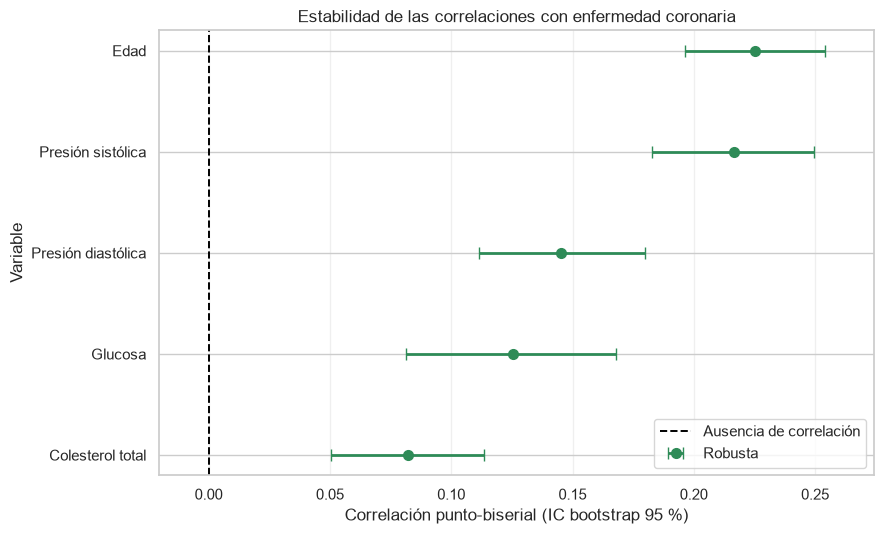

Figura guardada en: C:\MCDI501-Framingham\fase-3\sumativa-2\figuras\figura_3_estabilidad_correlaciones.png


In [16]:
nombres = list(resultados_correlaciones.keys())

r_observados = np.array([
    resultados_correlaciones[nombre]["r_observado"]
    for nombre in nombres
])

ic_inferiores = np.array([
    resultados_correlaciones[nombre]["ic_inferior"]
    for nombre in nombres
])

ic_superiores = np.array([
    resultados_correlaciones[nombre]["ic_superior"]
    for nombre in nombres
])

estados_robustos = [
    resultados_correlaciones[nombre]["robusta"]
    for nombre in nombres
]

posiciones = np.arange(len(nombres))

fig, eje = plt.subplots(figsize=(9, 5.5))

# Referencia de ausencia de correlación
eje.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.4,
    label="Ausencia de correlación",
    zorder=1
)

etiquetas_leyenda = set()

for posicion, r, inferior, superior, robusta in zip(
    posiciones,
    r_observados,
    ic_inferiores,
    ic_superiores,
    estados_robustos
):

    estado = "Robusta" if robusta else "Inestable"
    color = "#2E8B57" if robusta else "#E45756"

    etiqueta = (
        estado
        if estado not in etiquetas_leyenda
        else None
    )

    etiquetas_leyenda.add(estado)

    eje.errorbar(
        r,
        posicion,
        xerr=[
            [r - inferior],
            [superior - r]
        ],
        fmt="o",
        color=color,
        ecolor=color,
        markersize=7,
        capsize=4,
        elinewidth=2,
        label=etiqueta,
        zorder=2
    )

eje.set_yticks(posiciones)
eje.set_yticklabels(nombres)
eje.invert_yaxis()

# Asegurar que el cero quede visible
limite_inferior = min(
    0.0,
    float(ic_inferiores.min())
)

limite_superior = max(
    0.0,
    float(ic_superiores.max())
)

rango = limite_superior - limite_inferior
margen = 0.08 * rango

eje.set_xlim(
    limite_inferior - margen,
    limite_superior + margen
)

eje.set_title(
    "Estabilidad de las correlaciones con enfermedad coronaria"
)
eje.set_xlabel(
    "Correlación punto-biserial (IC bootstrap 95 %)"
)
eje.set_ylabel("Variable")
eje.grid(axis="x", alpha=0.30)
eje.legend()

plt.tight_layout()

DIR_FIGURAS.mkdir(
    parents=True,
    exist_ok=True
)

ruta_figura_correlaciones = (
    DIR_FIGURAS
    / "figura_3_estabilidad_correlaciones.png"
)

fig.savefig(
    ruta_figura_correlaciones,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta_figura_correlaciones
)

## 7. Simulación Monte Carlo basada en parámetros de la Sumativa 1

Se diseña una simulación Monte Carlo para estudiar la variabilidad de
la proporción de enfermedad coronaria en cohortes hipotéticas de
personas con características similares a las observadas en Framingham.

La simulación utilizará exclusivamente parámetros estimados en la
Sumativa 1:

- La proporción de personas con hipertensión previa.
- La proporción de enfermedad coronaria entre las personas con
  hipertensión.
- La proporción de enfermedad coronaria entre las personas sin
  hipertensión.

En cada iteración se generará una cohorte de 1.000 personas. Primero se
simulará la presencia o ausencia de hipertensión y luego la ocurrencia
de enfermedad coronaria según la tasa observada en cada grupo.

El procedimiento se repetirá 10.000 veces. En cada cohorte se registrará
la proporción de personas con enfermedad coronaria, lo que permitirá
estudiar su distribución, convergencia y posibles escenarios de riesgo.

La simulación reproduce asociaciones observadas en los datos y no debe
interpretarse como un modelo causal.

In [17]:
# Parámetros estimados en la Sumativa 1
proporcion_hipertension = (
    df_analisis["prevalentHyp"].mean()
)

tasa_chd_con_hipertension = (
    df_analisis.loc[
        df_analisis["prevalentHyp"] == 1,
        "TenYearCHD"
    ].mean()
)

tasa_chd_sin_hipertension = (
    df_analisis.loc[
        df_analisis["prevalentHyp"] == 0,
        "TenYearCHD"
    ].mean()
)

tasa_chd_global = (
    df_analisis["TenYearCHD"].mean()
)

print(
    "Proporción con hipertensión:",
    f"{proporcion_hipertension:.4f}"
)

print(
    "Tasa de CHD con hipertensión:",
    f"{tasa_chd_con_hipertension:.4f}"
)

print(
    "Tasa de CHD sin hipertensión:",
    f"{tasa_chd_sin_hipertension:.4f}"
)

print(
    "Tasa global observada de CHD:",
    f"{tasa_chd_global:.4f}"
)

Proporción con hipertensión: 0.3105
Tasa de CHD con hipertensión: 0.2470
Tasa de CHD sin hipertensión: 0.1092
Tasa global observada de CHD: 0.1520


In [18]:
# Configuración de la simulación
N_COHORTES = 10_000
TAMANO_COHORTE = 1_000

# Escenario adverso: 180 o más casos por cada 1.000 personas
UMBRAL_TASA = 0.18

# Generador independiente para esta sección
rng_monte_carlo = np.random.default_rng(SEMILLA)

# 1. Personas con hipertensión en cada cohorte
n_con_hipertension = rng_monte_carlo.binomial(
    n=TAMANO_COHORTE,
    p=proporcion_hipertension,
    size=N_COHORTES
)

# 2. Casos CHD entre quienes tienen hipertensión
casos_chd_con_hipertension = rng_monte_carlo.binomial(
    n=n_con_hipertension,
    p=tasa_chd_con_hipertension
)

# 3. Casos CHD entre quienes no tienen hipertensión
casos_chd_sin_hipertension = rng_monte_carlo.binomial(
    n=TAMANO_COHORTE - n_con_hipertension,
    p=tasa_chd_sin_hipertension
)

# 4. Casos y tasas totales por cohorte
casos_chd_totales = (
    casos_chd_con_hipertension
    + casos_chd_sin_hipertension
)

tasas_cohortes = (
    casos_chd_totales
    / TAMANO_COHORTE
)

# Valor esperado según los parámetros de la Sumativa 1
tasa_teorica = (
    proporcion_hipertension
    * tasa_chd_con_hipertension
    + (1 - proporcion_hipertension)
    * tasa_chd_sin_hipertension
)

# Resumen de las 10.000 cohortes
media_simulada = np.mean(tasas_cohortes)

desviacion_cohortes = np.std(
    tasas_cohortes,
    ddof=1
)

mcse_media = (
    desviacion_cohortes
    / np.sqrt(N_COHORTES)
)

p_2_5, p_97_5, p_99 = np.percentile(
    tasas_cohortes,
    [2.5, 97.5, 99]
)

probabilidad_umbral = np.mean(
    tasas_cohortes >= UMBRAL_TASA
)

# Media acumulada para estudiar convergencia
media_acumulada = (
    np.cumsum(tasas_cohortes)
    / np.arange(1, N_COHORTES + 1)
)

print("Número de cohortes:", N_COHORTES)
print("Personas por cohorte:", TAMANO_COHORTE)

print(
    f"Tasa global observada: "
    f"{tasa_chd_global:.4f}"
)

print(
    f"Tasa teórica calculada: "
    f"{tasa_teorica:.4f}"
)

print(
    f"Media simulada: "
    f"{media_simulada:.4f}"
)

print(
    f"Desviación entre cohortes: "
    f"{desviacion_cohortes:.4f}"
)

print(
    f"MCSE de la media simulada: "
    f"{mcse_media:.6f}"
)

print(
    f"Rango central simulado del 95 %: "
    f"[{p_2_5:.4f}, {p_97_5:.4f}]"
)

print(
    f"Percentil 99: "
    f"{p_99:.4f}"
)

print(
    f"Probabilidad de alcanzar o superar "
    f"{UMBRAL_TASA:.0%}: "
    f"{probabilidad_umbral:.4f}"
)

Número de cohortes: 10000
Personas por cohorte: 1000
Tasa global observada: 0.1520
Tasa teórica calculada: 0.1520
Media simulada: 0.1519
Desviación entre cohortes: 0.0113
MCSE de la media simulada: 0.000113
Rango central simulado del 95 %: [0.1300, 0.1740]
Percentil 99: 0.1790
Probabilidad de alcanzar o superar 18%: 0.0088


### 7.1. Resultados e interpretación

La tasa teórica de enfermedad coronaria calculada a partir de la
proporción de hipertensión y de las tasas observadas en cada grupo fue
de 15,20 %. La media de las 10.000 cohortes simuladas fue de 15,19 %,
prácticamente igual al valor teórico y a la tasa global observada. Esta
cercanía muestra que el mecanismo de simulación reproduce de forma
coherente los parámetros utilizados.

La desviación estándar entre cohortes fue de 1,13 puntos porcentuales.
Esta cantidad representa la variación esperable entre cohortes
hipotéticas de 1.000 personas, aun cuando todas se generen con las
mismas probabilidades. No corresponde a un error del algoritmo.

El error estándar Monte Carlo de la media fue de solo 0,0113 puntos
porcentuales. Por lo tanto, la media obtenida con 10.000 iteraciones
presenta muy poca incertidumbre numérica y la simulación es
suficientemente estable.

El 95 % central de las tasas simuladas quedó entre 13,0 % y 17,4 %.
Este rango describe la variabilidad de las cohortes generadas bajo los
parámetros fijados; no es un intervalo de confianza para la tasa
poblacional.

El percentil 99 fue 17,9 %, lo que indica que aproximadamente el 1 % de
las cohortes alcanzó tasas cercanas o superiores a ese nivel. Solo el
0,88 % alcanzó o superó el umbral analítico del 18 %, equivalente a 180
casos por cada 1.000 personas. Este umbral representa un escenario
adverso elegido para el análisis y no un punto de corte clínico.

La simulación supone independencia entre las personas y mantiene fijas
las tasas estimadas en la Sumativa 1. Por ello, representa variabilidad
entre cohortes, pero no incorpora la incertidumbre de los parámetros,
otros factores clínicos ni permite establecer relaciones causales.



### Figura 4. Distribución y convergencia de la simulación Monte Carlo

El panel izquierdo presenta la distribución de las tasas de enfermedad
coronaria obtenidas en las 10.000 cohortes simuladas. El panel derecho
muestra cómo la media acumulada se aproxima al valor teórico a medida
que aumenta el número de simulaciones.

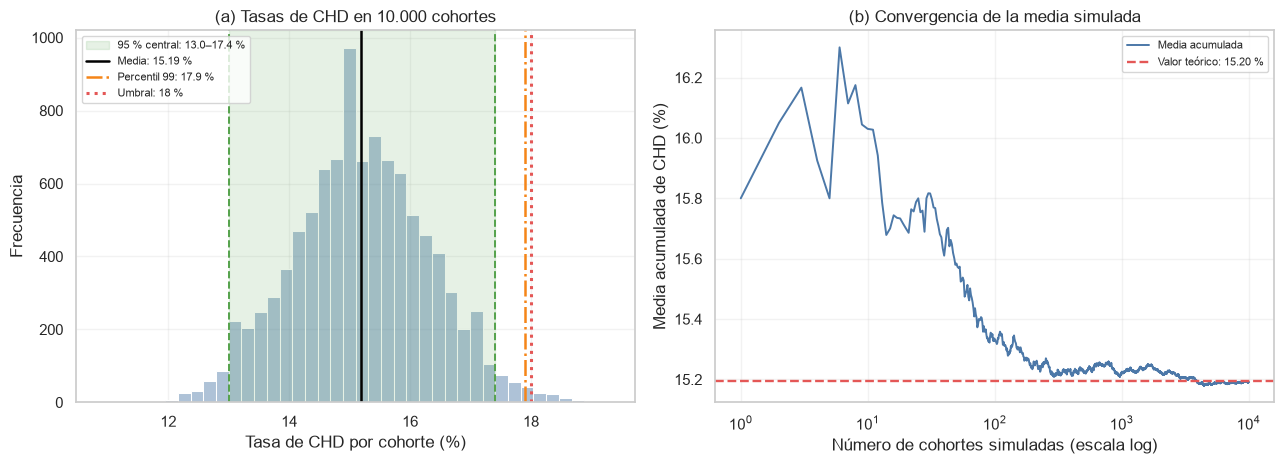

Figura guardada en: C:\MCDI501-Framingham\fase-3\sumativa-2\figuras\figura_4_monte_carlo_chd.png


In [19]:
fig, (eje_distribucion, eje_convergencia) = plt.subplots(
    1,
    2,
    figsize=(13, 4.8)
)

# Convertir las tasas a porcentajes
tasas_porcentaje = tasas_cohortes * 100
media_porcentaje = media_simulada * 100
p_2_5_porcentaje = p_2_5 * 100
p_97_5_porcentaje = p_97_5 * 100
p_99_porcentaje = p_99 * 100
umbral_porcentaje = UMBRAL_TASA * 100
teorica_porcentaje = tasa_teorica * 100

# Panel A: distribución de las tasas
sns.histplot(
    tasas_porcentaje,
    bins=40,
    color="#4C78A8",
    alpha=0.45,
    ax=eje_distribucion
)

# Rango central simulado del 95 %
eje_distribucion.axvspan(
    p_2_5_porcentaje,
    p_97_5_porcentaje,
    color="#54A24B",
    alpha=0.14,
    label=(
        f"95 % central: "
        f"{p_2_5_porcentaje:.1f}–"
        f"{p_97_5_porcentaje:.1f} %"
    )
)

eje_distribucion.axvline(
    p_2_5_porcentaje,
    color="#54A24B",
    linestyle="--",
    linewidth=1.4
)

eje_distribucion.axvline(
    p_97_5_porcentaje,
    color="#54A24B",
    linestyle="--",
    linewidth=1.4
)

# Media simulada
eje_distribucion.axvline(
    media_porcentaje,
    color="black",
    linewidth=1.8,
    label=f"Media: {media_porcentaje:.2f} %"
)

# Percentil 99
eje_distribucion.axvline(
    p_99_porcentaje,
    color="#F58518",
    linestyle="-.",
    linewidth=1.8,
    label=f"Percentil 99: {p_99_porcentaje:.1f} %"
)

# Umbral adverso
eje_distribucion.axvline(
    umbral_porcentaje,
    color="#E45756",
    linestyle=":",
    linewidth=2.2,
    label=f"Umbral: {umbral_porcentaje:.0f} %"
)

eje_distribucion.set_title(
    "(a) Tasas de CHD en 10.000 cohortes"
)
eje_distribucion.set_xlabel(
    "Tasa de CHD por cohorte (%)"
)
eje_distribucion.set_ylabel("Frecuencia")
eje_distribucion.legend(
    fontsize=8,
    loc="upper left"
)

# Panel B: convergencia
iteraciones = np.arange(
    1,
    N_COHORTES + 1
)

eje_convergencia.plot(
    iteraciones,
    media_acumulada * 100,
    color="#4C78A8",
    linewidth=1.4,
    label="Media acumulada"
)

eje_convergencia.axhline(
    teorica_porcentaje,
    color="#E45756",
    linestyle="--",
    linewidth=1.7,
    label=(
        f"Valor teórico: "
        f"{teorica_porcentaje:.2f} %"
    )
)

# Escala logarítmica para mostrar el inicio y el final
eje_convergencia.set_xscale("log")

eje_convergencia.set_title(
    "(b) Convergencia de la media simulada"
)
eje_convergencia.set_xlabel(
    "Número de cohortes simuladas (escala log)"
)
eje_convergencia.set_ylabel(
    "Media acumulada de CHD (%)"
)
eje_convergencia.legend(
    fontsize=8,
    loc="best"
)

for eje in (
    eje_distribucion,
    eje_convergencia
):
    eje.grid(alpha=0.25)

plt.tight_layout()

DIR_FIGURAS.mkdir(
    parents=True,
    exist_ok=True
)

ruta_figura_monte_carlo = (
    DIR_FIGURAS
    / "figura_4_monte_carlo_chd.png"
)

fig.savefig(
    ruta_figura_monte_carlo,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta_figura_monte_carlo
)

## 8. Análisis de robustez

Se comparan la media original, mediana, media recortada al 5 % y media
winsorizada entre los percentiles 1 y 99. Un jackknife identifica la
observación que más modifica cada media. Además, se repite la comparación
de presión sistólica tras winsorizar y se obtiene un IC bootstrap para la
diferencia recortada. La winsorización es solo un análisis de sensibilidad:
no modifica los datos originales.

In [20]:
variables_robustez = {
    "Edad": "age", "Presión sistólica": "sysBP",
    "Colesterol total": "totChol"
}
filas_robustez_medias = []

for nombre, variable in variables_robustez.items():
    serie = df_analisis[variable].dropna()
    x = serie.to_numpy()
    n = len(x)
    media = np.mean(x)
    p1, p99 = np.percentile(x, [1, 99])
    jack = (np.sum(x) - x) / (n - 1)
    cambios = np.abs(jack - media)
    pos = int(np.argmax(cambios))
    ee_jack = np.sqrt((n - 1) / n * np.sum((jack - np.mean(jack)) ** 2))
    filas_robustez_medias.append({
        "Variable": nombre, "n": n, "Media original": media,
        "Mediana": np.median(x),
        "Media recortada 5 %": stats.trim_mean(x, 0.05),
        "Media winsorizada 1–99 %": np.mean(np.clip(x, p1, p99)),
        "EE jackknife": ee_jack,
        "Índice influyente": int(serie.index[pos]),
        "Valor influyente": x[pos],
        "Cambio máximo al omitir": cambios[pos]
    })

tabla_robustez_medias = pd.DataFrame(filas_robustez_medias)
display(tabla_robustez_medias.round(4))

,Variable,n,Media original,Mediana,Media recortada 5 %,Media winsorizada 1–99 %,EE jackknife,Índice influyente,Valor influyente,Cambio máximo al omitir
0,Edad,4238,49.5849,49.0,49.4471,49.5833,0.1317,1624,70.0,0.0048
1,Presión sistólica,4238,132.3524,128.0,130.9057,132.2400,0.3385,481,295.0,0.0384
2,Colesterol total,4188,236.7216,234.0,235.1934,236.4072,0.6890,3160,696.0,0.1097


### 8.1. Sensibilidad de la diferencia de presión sistólica

Se winsoriza `sysBP` globalmente en los percentiles 1 y 99, manteniendo
todas las filas. También se compara la media recortada al 5 % de cada grupo
y se calcula un IC bootstrap percentil con 5.000 remuestras.

In [21]:
datos_rob = df_analisis[["sysBP", "TenYearCHD"]].dropna().copy()
p1_sys, p99_sys = np.percentile(datos_rob["sysBP"], [1, 99])
datos_rob["sysBP_w"] = datos_rob["sysBP"].clip(p1_sys, p99_sys)

con = datos_rob.loc[datos_rob["TenYearCHD"] == 1, "sysBP"].to_numpy()
sin = datos_rob.loc[datos_rob["TenYearCHD"] == 0, "sysBP"].to_numpy()
con_w = datos_rob.loc[datos_rob["TenYearCHD"] == 1, "sysBP_w"].to_numpy()
sin_w = datos_rob.loc[datos_rob["TenYearCHD"] == 0, "sysBP_w"].to_numpy()

dif_w = np.mean(con_w) - np.mean(sin_w)
dif_trim = stats.trim_mean(con, 0.05) - stats.trim_mean(sin, 0.05)
t_orig, p_welch_orig = stats.ttest_ind(con, sin, equal_var=False)
t_w, p_welch_w = stats.ttest_ind(con_w, sin_w, equal_var=False)

def d_cohen(a, b):
    n1, n0 = len(a), len(b)
    vp = ((n1 - 1) * np.var(a, ddof=1) + (n0 - 1) * np.var(b, ddof=1)) / (n1 + n0 - 2)
    return (np.mean(a) - np.mean(b)) / np.sqrt(vp)

rng_rob = np.random.default_rng(SEMILLA)
N_BOOTSTRAP_ROBUSTEZ = 5_000
dif_trim_boot = np.empty(N_BOOTSTRAP_ROBUSTEZ)
for i in range(N_BOOTSTRAP_ROBUSTEZ):
    a = rng_rob.choice(con, size=len(con), replace=True)
    b = rng_rob.choice(sin, size=len(sin), replace=True)
    dif_trim_boot[i] = stats.trim_mean(a, 0.05) - stats.trim_mean(b, 0.05)
ic_dif_trim = np.percentile(dif_trim_boot, [2.5, 97.5])

tabla_robustez_diferencia = pd.DataFrame([
    ["Media original", diferencia_observada, 0, p_welch_orig, d_cohen(con, sin)],
    ["Media winsorizada 1–99 %", dif_w, 100 * (dif_w / diferencia_observada - 1), p_welch_w, d_cohen(con_w, sin_w)],
    ["Media recortada 5 %", dif_trim, 100 * (dif_trim / diferencia_observada - 1), np.nan, np.nan]
], columns=["Estimador", "Diferencia (mmHg)", "Cambio (%)", "p de Welch", "d de Cohen"])

display(tabla_robustez_diferencia.round(4))
print(f"Límites winsorización: [{p1_sys:.1f}, {p99_sys:.1f}] mmHg")
print(f"IC bootstrap 95 % diferencia recortada: [{ic_dif_trim[0]:.3f}, {ic_dif_trim[1]:.3f}] mmHg")

,Estimador,Diferencia (mmHg),Cambio (%),p de Welch,d de Cohen
0,Media original,13.2852,0.0000,0.0,0.6174
1,Media winsorizada 1–99 %,12.7842,-3.7708,0.0,0.6111
2,Media recortada 5 %,13.1515,-1.0065,NaN,NaN


Límites winsorización: [97.0, 200.0] mmHg
IC bootstrap 95 % diferencia recortada: [10.992, 15.353] mmHg


### 8.2. Sensibilidad de las correlaciones

Cada variable clínica se limita entre sus percentiles 1 y 99 y se vuelve a
correlacionar con `TenYearCHD` para comprobar si el signo depende de unos
pocos valores extremos.

In [22]:
filas_robustez_correlaciones = []
for nombre, variable in variables_correlacion_bootstrap.items():
    pares = df_analisis[[variable, "TenYearCHD"]].dropna().copy()
    p1, p99 = np.percentile(pares[variable], [1, 99])
    rw = pares[variable].clip(p1, p99).corr(pares["TenYearCHD"])
    r0 = pares[variable].corr(pares["TenYearCHD"])
    filas_robustez_correlaciones.append({
        "Variable": nombre, "r original": r0, "r winsorizada": rw,
        "Cambio absoluto": abs(rw - r0),
        "Conserva signo": np.sign(r0) == np.sign(rw)
    })
tabla_robustez_correlaciones = pd.DataFrame(filas_robustez_correlaciones)
display(tabla_robustez_correlaciones.round(4))

,Variable,r original,r winsorizada,Cambio absoluto,Conserva signo
0,Edad,0.2253,0.2252,0.0001,True
1,Presión sistólica,0.2164,0.2143,0.0021,True
2,Presión diastólica,0.1453,0.1453,0.0001,True
3,Glucosa,0.1255,0.1088,0.0168,True
4,Colesterol total,0.0822,0.0809,0.0013,True


### Figura 5. Comparación de estimadores robustos

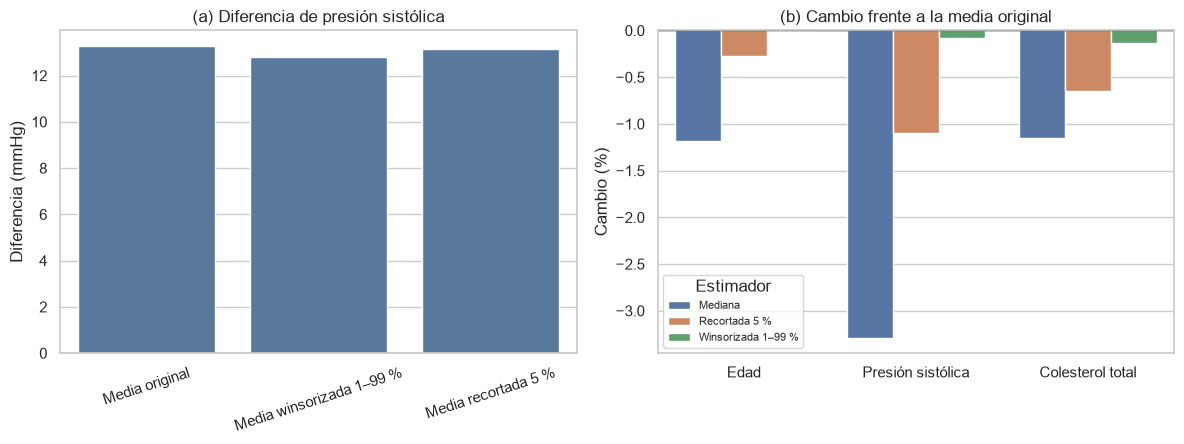

Figura guardada en: C:\MCDI501-Framingham\fase-3\sumativa-2\figuras\figura_5_analisis_robustez.png


In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(data=tabla_robustez_diferencia, x="Estimador", y="Diferencia (mmHg)", color="#4C78A8", ax=ax1)
ax1.axhline(0, color="black", linewidth=1)
ax1.set_title("(a) Diferencia de presión sistólica")
ax1.set_xlabel("")
ax1.tick_params(axis="x", rotation=18)

filas_cambios = []
for _, fila in tabla_robustez_medias.iterrows():
    for etiqueta, columna in {
        "Mediana": "Mediana", "Recortada 5 %": "Media recortada 5 %",
        "Winsorizada 1–99 %": "Media winsorizada 1–99 %"
    }.items():
        filas_cambios.append({"Variable": fila["Variable"], "Estimador": etiqueta,
            "Cambio (%)": 100 * (fila[columna] / fila["Media original"] - 1)})
tabla_cambios_estimadores = pd.DataFrame(filas_cambios)
sns.barplot(data=tabla_cambios_estimadores, x="Variable", y="Cambio (%)", hue="Estimador", ax=ax2)
ax2.axhline(0, color="black", linewidth=1)
ax2.set_title("(b) Cambio frente a la media original")
ax2.set_xlabel("")
ax2.legend(fontsize=8, title="Estimador")
plt.tight_layout()
ruta_figura_robustez = DIR_FIGURAS / "figura_5_analisis_robustez.png"
fig.savefig(ruta_figura_robustez, dpi=300, bbox_inches="tight")
plt.show()
print("Figura guardada en:", ruta_figura_robustez)

### 8.3. Interpretación

Edad es prácticamente insensible a los extremos. Para presión sistólica y
colesterol, las medias robustas permanecen cercanas a las originales,
aunque las medianas menores revelan colas derechas. La influencia de una
sola observación es pequeña por el gran tamaño muestral.

La diferencia de presión sistólica conserva signo, magnitud aproximada y
significancia tras winsorizar; el IC bootstrap de la diferencia recortada no
incluye cero. La asociación no ajustada es robusta frente a estas decisiones,
pero no implica causalidad. Las cinco correlaciones conservan signo;
glucosa es la más sensible y requiere cautela. Sus magnitudes siguen siendo
débiles o modestas y no prueban capacidad predictiva.

## 9. Resultados validados y preparación para la Sumativa 3

In [24]:
glucosa_rob = tabla_robustez_correlaciones.query("Variable == 'Glucosa'").iloc[0]
tabla_preparacion_s3 = pd.DataFrame([
    ["Medias de edad, sysBP y colesterol", "IC clásico, percentil y BCa", "Límites casi coincidentes", "Robusto", "Controlar extremos dentro del entrenamiento"],
    ["Diferencia sysBP según CHD", "Permutación, winsorización y recorte", f"{diferencia_observada:.2f} original; {dif_w:.2f} winsorizada; p={p_permutacion:.5f}", "Robusto como asociación", "Ajustar por confusores; no inferir causalidad"],
    ["Correlaciones con CHD", "Bootstrap pareado y winsorización", f"r entre {r_observados.min():.3f} y {r_observados.max():.3f}; IC excluyen 0", "Estable pero débil", "No elegir predictores solo por correlación marginal"],
    ["Glucosa", "Sensibilidad a extremos y n efectivo", f"r={glucosa_rob['r original']:.4f} a {glucosa_rob['r winsorizada']:.4f}; n=3850", "Usar con cautela", "Estudiar extremos y faltantes"],
    ["Tasa global CHD", "10.000 cohortes Monte Carlo", f"15,20 % observada; {media_simulada*100:.2f} % simulada; MCSE={mcse_media*100:.4f} pp", "Coherente con parámetros fijos", "Estratificar y validar fuera de muestra"],
    ["Valores extremos", "Jackknife y estimadores robustos", "sysBP=295; colesterol=696", "Revisar antes de modelar", "Verificar plausibilidad; transformar dentro del entrenamiento"],
    ["Datos faltantes", "Tamaños efectivos", "Glucosa n=3850; colesterol n=4188; total n=4238", "Revisar antes de modelar", "Imputar dentro de cada partición"]
], columns=["Resultado de S1", "Validación S2", "Evidencia numérica", "Estado", "Recomendación S3"])
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
ruta_tabla_s3 = DIR_RESULTADOS / "resultados_validados_para_s3.csv"
tabla_preparacion_s3.to_csv(ruta_tabla_s3, index=False, encoding="utf-8-sig")
display(tabla_preparacion_s3)
print("Tabla guardada en:", ruta_tabla_s3)

,Resultado de S1,Validación S2,Evidencia numérica,Estado,Recomendación S3
0,"Medias de edad, sysBP y colesterol","IC clásico, percentil y BCa",Límites casi coincidentes,Robusto,Controlar extremos dentro del entrenamiento
1,Diferencia sysBP según CHD,"Permutación, winsorización y recorte",13.29 original; 12.78 winsorizada; p=0.00010,Robusto como asociación,Ajustar por confusores; no inferir causalidad
2,Correlaciones con CHD,Bootstrap pareado y winsorización,r entre 0.082 y 0.225; IC excluyen 0,Estable pero débil,No elegir predictores solo por correlación mar...
3,Glucosa,Sensibilidad a extremos y n efectivo,r=0.1255 a 0.1088; n=3850,Usar con cautela,Estudiar extremos y faltantes
4,Tasa global CHD,10.000 cohortes Monte Carlo,"15,20 % observada; 15.19 % simulada; MCSE=0.01...",Coherente con parámetros fijos,Estratificar y validar fuera de muestra
5,Valores extremos,Jackknife y estimadores robustos,sysBP=295; colesterol=696,Revisar antes de modelar,Verificar plausibilidad; transformar dentro de...
6,Datos faltantes,Tamaños efectivos,Glucosa n=3850; colesterol n=4188; total n=4238,Revisar antes de modelar,Imputar dentro de cada partición


Tabla guardada en: C:\MCDI501-Framingham\fase-3\sumativa-2\resultados\resultados_validados_para_s3.csv


### 9.1. Recomendaciones metodológicas

En la Sumativa 3 se debe dividir antes de imputar, escalar, transformar o
winsorizar, ajustando cada operación solo con el entrenamiento para evitar
fuga de información. Como `TenYearCHD` ocurre en 15,2 %, conviene
estratificar y evaluar discriminación y calibración fuera de muestra. Edad
y presión sistólica son candidatas para el modelo multivariado, junto con
sexo, tabaquismo y otros factores. Deben mantenerse separadas asociación,
predicción y causalidad.

## 10. Referencias

- Dileep. (2019). *Logistic regression to predict heart disease* [Datos]. Kaggle.
- Efron, B. (1987). Better bootstrap confidence intervals. *JASA, 82*(397), 171–185.
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Good, P. I. (2005). *Permutation, parametric, and bootstrap tests* (3.ª ed.). Springer.
- National Heart, Lung, and Blood Institute. (s. f.). *Framingham Heart Study*.
- Robert, C. P., & Casella, G. (2004). *Monte Carlo statistical methods* (2.ª ed.). Springer.
- Virtanen, P., et al. (2020). SciPy 1.0. *Nature Methods, 17*(3), 261–272.

In [25]:
figuras_esperadas = [
    DIR_FIGURAS / "figura_1_bootstrap_intervalos.png",
    DIR_FIGURAS / "figura_2_permutacion_presion_sistolica.png",
    DIR_FIGURAS / "figura_3_estabilidad_correlaciones.png",
    DIR_FIGURAS / "figura_4_monte_carlo_chd.png",
    DIR_FIGURAS / "figura_5_analisis_robustez.png"
]
for ruta in figuras_esperadas:
    assert ruta.exists(), f"No se encontró {ruta.name}"
assert ruta_tabla_s3.exists()
assert p_permutacion < 0.05
assert ic_dif_trim[0] > 0
assert tabla_robustez_correlaciones["Conserva signo"].all()
assert abs(media_simulada - tasa_teorica) < 0.001
print("Verificación final completada sin errores.")
print("Figuras verificadas:", len(figuras_esperadas))
print("Semilla reproducible:", SEMILLA)

Verificación final completada sin errores.
Figuras verificadas: 5
Semilla reproducible: 42
